In [1]:
#import needed libraries
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
import keras
keras.mixed_precision.set_global_policy("mixed_float16")
from pathlib import Path
from PIL import Image
import numpy as np
# Local files/code
from src.agents.U_NET import UNET
import src.data_preprocessing.image_preprocessing as image_pre
import cv2
import matplotlib.pyplot as plt


I0000 00:00:1794866375.310376    2997 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794866377.287918    2997 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
##Set IMG SIZE AND BATCH SIZE for model initialization
IMG_SIZE = (384,384)
BATCH_SIZE = 16

In [3]:
#Load all of the corresponding image mask paths
root_img_path = Path.cwd() / 'data' / 'plantseg' / 'images' 
root_mask_path = Path.cwd() / 'data' / 'plantseg' / 'annotations' 

train_image_path = Path.cwd() / 'data' / 'plantseg' / 'images' / 'train_384'
train_mask_path = Path.cwd() / 'data' / 'plantseg' / 'annotations' / 'train_binarized_384'

test_image_path = Path.cwd() / 'data' / 'plantseg' / 'images' / 'test_384'
test_mask_path = Path.cwd() / 'data' / 'plantseg' / 'annotations' / 'test_binarized_384'

val_image_path = Path.cwd() / 'data' / 'plantseg' / 'images' / 'val_384'
val_mask_path = Path.cwd() / 'data' / 'plantseg' / 'annotations' / 'val_binarized_384'

In [4]:
#Create datasets that can be utilized for model training
train_df = image_pre.generate_unet_dataset(train_image_path, train_mask_path, img_size=(384,384), batch_size=BATCH_SIZE, training=True)
val_df = image_pre.generate_unet_dataset(val_image_path, val_mask_path, img_size=(384,384), batch_size=BATCH_SIZE, training=False)
test_df = image_pre.generate_unet_dataset(test_image_path, test_mask_path, img_size=(384,384), batch_size=BATCH_SIZE, training=False)

In [5]:
#initialize UNet Model Build and Compile the model to prepare for training
model = UNET(img_size=IMG_SIZE, dropout_value=0.13, add_dropout=True)
model.build_unet((*IMG_SIZE, 3))
model.compile(lr=1e-4, wd=.001)


In [6]:
history = model.fit(train_df, val_df, epochs=60)
save_path = './models/unet_best_dropout_2.keras'
model.save(save_path)

Epoch 1/60


E0000 00:00:1794866423.162849    2997 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


706/706 ━━━━━━━━━━━━━━━━━━━━ 301s 400ms/step - BIoU: 0.5389 - Disease_BIoU: 0.3435 - MACRO_f1_score: 0.5113 - Precision: 0.4454 - Recall: 0.6002 - accuracy: 0.7667 - loss: 1.1332 - val_BIoU: 0.5858 - val_Disease_BIoU: 0.3908 - val_MACRO_f1_score: 0.5619 - val_Precision: 0.4991 - val_Recall: 0.6429 - val_accuracy: 0.8079 - val_loss: 1.0275 - learning_rate: 1.0000e-04
Epoch 2/60
706/706 ━━━━━━━━━━━━━━━━━━━━ 278s 394ms/step - BIoU: 0.5988 - Disease_BIoU: 0.3972 - MACRO_f1_score: 0.5686 - Precision: 0.5656 - Recall: 0.5716 - accuracy: 0.8236 - loss: 0.9908 - val_BIoU: 0.6016 - val_Disease_BIoU: 0.3745 - val_MACRO_f1_score: 0.5449 - val_Precision: 0.6209 - val_Recall: 0.4856 - val_accuracy: 0.8446 - val_loss: 0.9599 - learning_rate: 1.0000e-04
Epoch 3/60
706/706 ━━━━━━━━━━━━━━━━━━━━ 277s 393ms/step - BIoU: 0.6269 - Disease_BIoU: 0.4354 - MACRO_f1_score: 0.6066 - Precision: 0.6096 - Recall: 0.6037 - accuracy: 0.8408 - loss: 0.9255 - val_BIoU: 0.6209 - val_Disease_BIoU: 0.4089 - val_MACRO_f1_

In [ ]:
#produce groups of all of the items measured in history

In [7]:
#evaluate the test data
eval_scores = model.model.evaluate(test_df, return_dict=True)

102/102 ━━━━━━━━━━━━━━━━━━━━ 12s 114ms/step - BIoU: 0.7132 - Disease_BIoU: 0.5602 - MACRO_f1_score: 0.7182 - Precision: 0.7246 - Recall: 0.7118 - accuracy: 0.8856 - loss: 0.7533


In [8]:
print(eval_scores)

{'BIoU': 0.7131878137588501, 'Disease_BIoU': 0.5602478981018066, 'MACRO_f1_score': 0.7181524634361267, 'Precision': 0.7245815992355347, 'Recall': 0.7118364572525024, 'accuracy': 0.8856335878372192, 'loss': 0.7532767057418823}


In [ ]:
#Grab all metrics from Training
loss = history.history['loss']
val_loss = history.history['val_loss']
biou = history.history['BIoU']
val_biou = history.history['val_BIoU']
disease_biou = history.history['Disease_BIoU']
val_disease_biou = history.history['val_Disease_BIoU']
MacroF1 = history.history['MACRO_f1_score']
val_MacroF1 = history.history['val_MACRO_f1_score']
precision = history.history['Precision']
val_precision = history.history['val_Precision']
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']
recall = history.history['Recall']
val_recall = history.history['val_Recall']


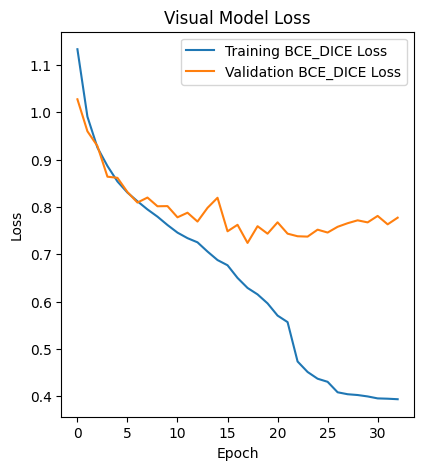

In [ ]:
#Plot UNET Model Loss
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 2)
plt.plot(loss, label='Training BCE_DICE Loss')
plt.plot(val_loss, label='Validation BCE_DICE Loss')
plt.title('Visual Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

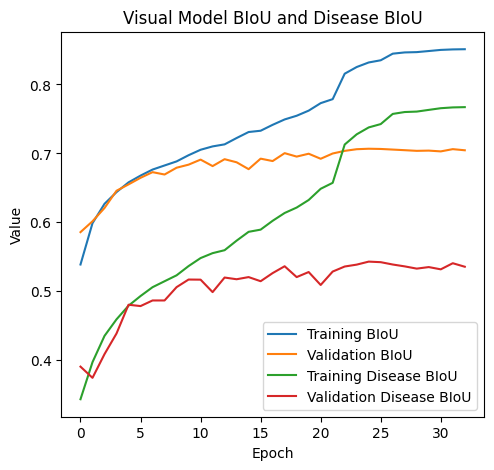

In [ ]:
#Plot Scores for BIoU and Disease BIoU
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 2)
plt.plot(biou, label='Training BIoU')
plt.plot(val_biou, label='Validation BIoU')
plt.plot(disease_biou, label='Training Disease BIoU')
plt.plot(val_disease_biou, label='Validation Disease BIoU')
plt.title('Visual Model BIoU and Disease BIoU')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()

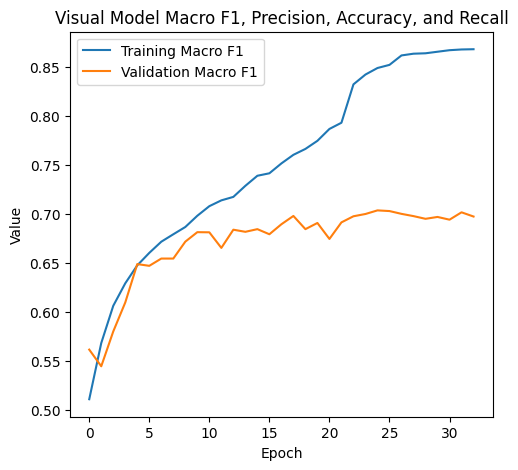

In [26]:
#Plot Scores for Macro F1, Precision, Accuracy, and Recall
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(MacroF1, label='Training Macro F1')
plt.plot(val_MacroF1, label='Validation Macro F1')
plt.title('Visual Model Macro F1, Precision, Accuracy, and Recall')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


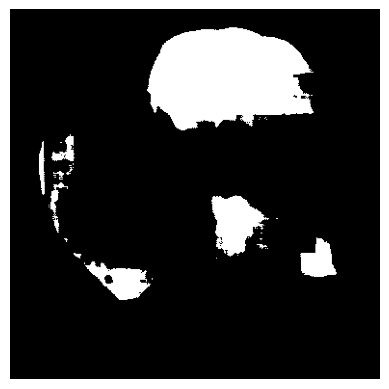

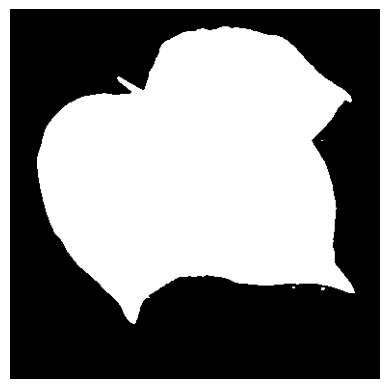

In [ ]:
#grab an image from the plant VQA dataset
image = Image.open(r'../../data/PlantExpertVQA/images/0ad07c99921df75a.jpg')
#perform needed image options to prep the image to be intook by the model
image = np.asarray(image)
image = cv2.resize(image, (384,384))

#Divide by 255 to push the values in the image into a range of 0-1
image = image.astype(np.float32) / 255.0

#convert to np.ndarray
mask = best.predict(image)

#threshold the mask, any probability values 70% or over will be converted to 1, so when multiplied by 255 they become white pixels
mask = (mask > 0.7).astype(np.uint8) * 255
#remove the batch size element that is returned from keras
mask = mask.squeeze()

#Display the mask generated by the model
plt.imshow(mask, cmap='gray') ; plt.axis('off') ; plt.show()

#Get a count of how many pixels were labeled as diseased
vals, counts = np.unique_counts(mask)

plt.imshow(image) ; plt.axis('off') ; plt.show()
